# Retail Sales Prediction Using Python and Linear Regression

## Project Overview

This project analyzes 1,000 retail sales records to explore customer spending patterns, examine relationships between transaction characteristics and total spending, and evaluate a baseline Linear Regression model.

## Business Objectives

- Explore the distribution of retail transaction spending.
- Examine spending patterns across product categories.
- Identify relationships between quantity, unit price, customer demographics, and total spending.
- Build and evaluate a baseline Linear Regression model.
- Communicate findings, model limitations, and potential business applications.

## Tools and Technologies

- **Python:** Data analysis and modeling
- **Pandas and NumPy:** Data manipulation and numerical calculations
- **Matplotlib and Seaborn:** Data visualization
- **Scikit-learn:** Model training and evaluation
- **Jupyter Notebook:** Analysis documentation and reporting

## Dataset Description

The dataset contains 1,000 retail sales records and seven original columns: CustomerID, Age, Gender, ProductCategory, Quantity, UnitPrice, and TotalSpending.

The dataset is used for portfolio practice and does not represent verified real-world business transactions.

## 1. Import Libraries

The analysis uses Pandas and NumPy for data manipulation and numerical operations, Matplotlib and Seaborn for exploratory visualizations, and Scikit-learn for predictive modeling and evaluation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('retail_sales_prediction_1000.csv')

In [3]:
df.head()

,CustomerID,Age,Gender,ProductCategory,Quantity,UnitPrice,TotalSpending
0,1,56,Male,Electronics,8,490.68,3925.44
1,2,69,Male,Clothing,5,99.10,495.50
2,3,46,Male,Sports,7,397.33,2781.31
3,4,32,Female,Sports,4,454.41,1817.64
4,5,60,Male,Home & Kitchen,4,472.13,1888.52


## 3. Data Inspection and Quality Assessment

The dataset was examined to understand its structure, data types, completeness, and statistical characteristics.

The `df.info()` function confirmed that the dataset contains 1,000 records and seven columns. All seven columns have 1,000 non-null values, indicating no missing values in the dataset.

The dataset includes five numerical columns and two categorical columns.

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   CustomerID       1000 non-null   int64  
 1   Age              1000 non-null   int64  
 2   Gender           1000 non-null   object 
 3   ProductCategory  1000 non-null   object 
 4   Quantity         1000 non-null   int64  
 5   UnitPrice        1000 non-null   float64
 6   TotalSpending    1000 non-null   float64
dtypes: float64(2), int64(3), object(2)
memory usage: 54.8+ KB


### Descriptive Statistics

Descriptive statistics were generated to examine the distribution, central tendency, and variability of numerical variables.

**Key findings:**

- The average customer age is approximately 44 years.
- The average purchase quantity is 5.56 units.

- The average unit price is $260.63.

- Average total spending per transaction is $1,456.69.


- Total spending ranges from $14.92     to      $4,998.50.


These statistics provide an initial understanding of transaction values and purchasing patterns in the dataset.

In [5]:
# Check missing values
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
CustomerID         0
Age                0
Gender             0
ProductCategory    0
Quantity           0
UnitPrice          0
TotalSpending      0
dtype: int64


In [6]:
# Check duplicate records
print("\nDuplicate Records:", df.duplicated().sum())


Duplicate Records: 0


In [7]:
# Check dataset dimensions
print("\nDataset Shape:", df.shape)



Dataset Shape: (1000, 7)


In [8]:
df.describe()

,CustomerID,Age,Quantity,UnitPrice,TotalSpending
count,1000.000000,1000.000000,1000.000000,1000.000000,1000.000000
mean,500.500000,44.429000,5.563000,260.634350,1456.685290
std,288.819436,15.772309,2.862206,140.048797,1161.938171
min,1.000000,18.000000,1.000000,11.740000,14.920000
25%,250.750000,30.000000,3.000000,144.165000,469.482500
50%,500.500000,44.000000,6.000000,263.605000,1169.490000
75%,750.250000,58.250000,8.000000,380.665000,2198.235000
max,1000.000000,70.000000,10.000000,499.970000,4998.500000


### Data Quality Assessment — Findings

The dataset was assessed for missing values, duplicate records, and structural consistency.

**Key findings:**

- No missing values were identified across the dataset.
- No fully duplicated records were detected.
- The dataset contains 1,000 observations and seven original variables.
- An additional feature, `Quantity_UnitPrice`, was created during feature engineering, increasing the working dataset to eight columns.

**Conclusion:** The dataset passed the initial completeness and duplicate checks. No missing-value imputation or duplicate removal was required. Further validation confirmed that `TotalSpending` equals `Quantity × UnitPrice` across all 1,000 observations.

In [9]:
df.shape

(1000, 7)

#### EDA Analysis

## 4. Exploratory Data Analysis (EDA)

### 4.1 Distribution of Total Spending

**Objective:** Examine the distribution of transaction spending to understand typical purchase values, spending variability, and the presence of high-value transactions.

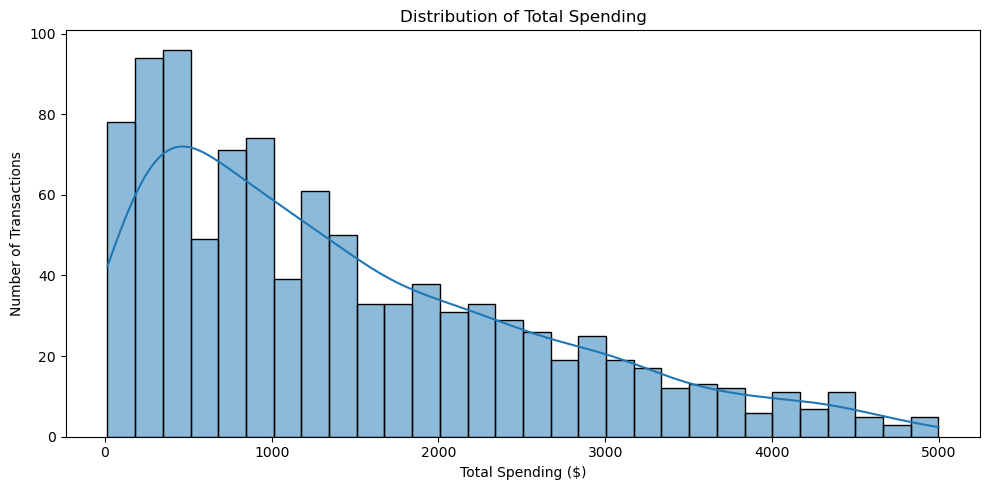

In [10]:

plt.figure(figsize=(10, 5))

sns.histplot(
    df['TotalSpending'],
    bins=30,
    kde=True
)

plt.title('Distribution of Total Spending')
plt.xlabel('Total Spending ($)')
plt.ylabel('Number of Transactions')
plt.tight_layout()
plt.show()


#### Interpretation and Business Insight

The retail sales dataset has an average transaction value of $1,456.69 and a median of $1,169.49. The higher mean suggests that the spending distribution is positively skewed, with larger transactions increasing the overall average.

Transaction values range from $14.92 to $4,998.50, indicating substantial variation in purchase amounts.

**Business relevance:** Understanding the distribution of transaction values can help retailers identify spending segments and investigate opportunities to improve average transaction value. Further analysis would be required to determine which customer groups contribute most to revenue.


### 4.2 Spending by Product Category

**Objective:** Compare transaction spending across product categories to identify differences in median spending, variability, and potential high-value transactions.

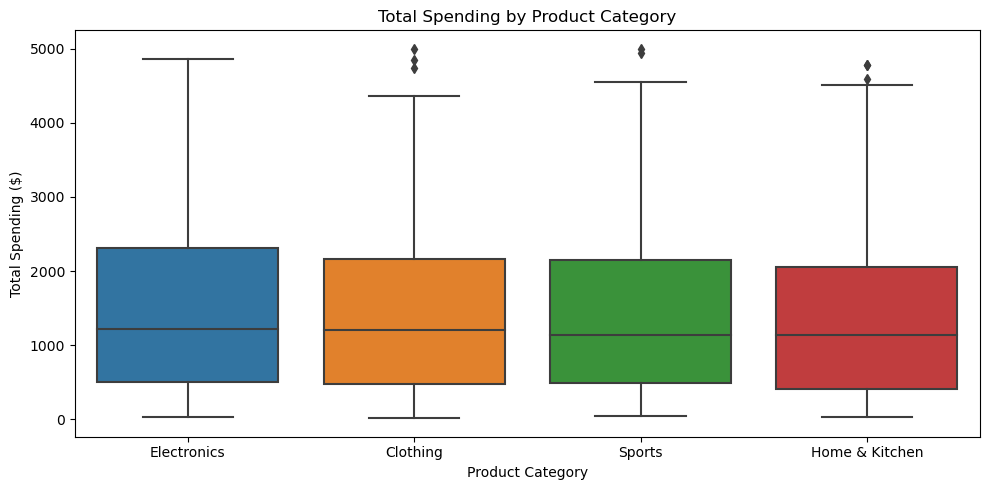

In [11]:

plt.figure(figsize=(10, 5))

sns.boxplot(
    x='ProductCategory',
    y='TotalSpending',
    data=df
)

plt.title('Total Spending by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Spending ($)')
plt.tight_layout()
plt.show()


##
calculate the exact spending statistics for each category.

In [12]:

category_summary = (
    df.groupby('ProductCategory')['TotalSpending']
    .agg(['count', 'mean', 'median', 'min', 'max'])
    .round(2)
    .sort_values('median', ascending=False)
)

category_summary


,count,mean,median,min,max
ProductCategory,,,,,
Electronics,261,1501.53,1212.12,33.14,4858.0
Clothing,232,1441.10,1201.85,14.92,4997.5
Home & Kitchen,269,1399.29,1143.42,32.30,4779.4
Sports,238,1487.56,1134.28,44.84,4998.5


#### Interpretation and Business Insights

The analysis compared transaction spending across Electronics, Clothing, Home & Kitchen, and Sports.

**Key findings:**

- Electronics recorded the highest average transaction spending ($1,501.53) and median spending ($1,212.12).

- Home & Kitchen recorded the highest transaction count (269), but the lowest average spending ($1,399.29).

- Sports recorded an average transaction value of $1,487.56, compared with a median of $1,134.28, indicating that higher-value
transactions raise its average.

- Median transaction values were relatively similar across categories, ranging from $1,134.28 to $1,212.12.

**Business relevance:** These results suggest opportunities to investigate high-value transactions, pricing, and purchase 
quantities across product categories. However, further analysis is needed before recommending specific pricing or promotional changes.

### 4.3 Correlation Analysis

**Objective:** Examine the strength and direction of linear relationships between customer age, purchase quantity, unit price, and total spending using a correlation heatmap.

Correlation coefficients range from -1 to +1. Values close to +1 indicate strong positive linear relationships, values close to -1 indicate strong negative linear relationships, and values near zero indicate weak linear relationships.

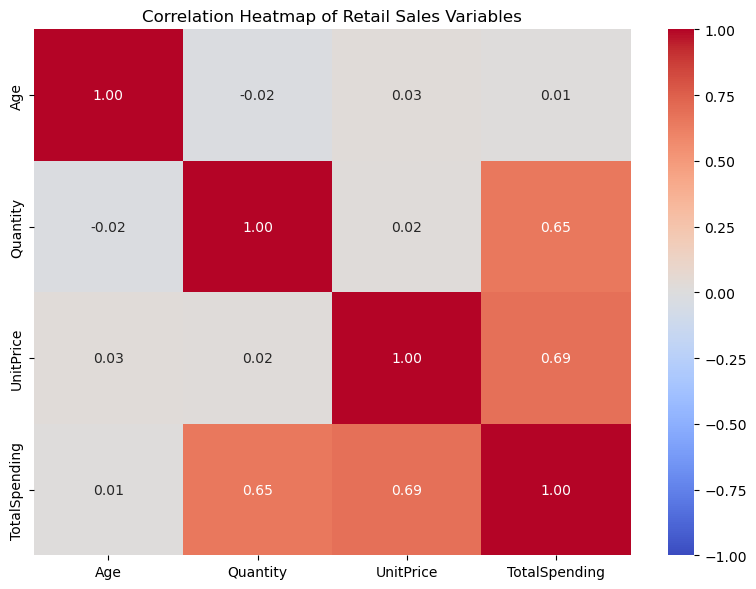

In [13]:

# Select numerical variables
corr = df[
    ['Age', 'Quantity', 'UnitPrice', 'TotalSpending']
].corr()

# Create correlation heatmap
plt.figure(figsize=(8, 6))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    center=0,
    fmt='.2f',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Heatmap of Retail Sales Variables')
plt.tight_layout()
plt.show()


### Display the actual correlation values

In [14]:

# Correlation with Total Spending
corr['TotalSpending'].sort_values(ascending=False)


TotalSpending    1.000000
UnitPrice        0.686702
Quantity         0.649749
Age              0.009466
Name: TotalSpending, dtype: float64

#### Interpretation and Business Insights

The correlation analysis examined relationships between customer age, purchase quantity, unit price, and total transaction spending.

**Key findings:**

- **Unit Price (r = 0.6867):** A moderately strong positive correlation indicates that transactions involving higher-priced products tend to have higher total spending.
- **Quantity (r = 0.6497):** A moderately strong positive correlation suggests that transactions involving larger quantities are associated with higher spending.
- **Age (r = 0.0095):** The correlation is close to zero, indicating almost no linear relationship between customer age and total spending.

**Business relevance:** Quantity and unit price are the variables most strongly associated with total transaction spending in this analysis. However, because total spending is mathematically calculated as Quantity multiplied by Unit Price, these relationships are expected and should not be interpreted as independent causal findings.

**Conclusion:** The analysis demonstrates how correlation can identify linear associations between numerical variables and support exploratory data analysis.

## 5. Feature Engineering

### 5.1 Feature Selection

The dataset was divided into independent variables (X) and the target variable (y) for Linear Regression modeling.

**Predictor variables (X):**

- Age: Customer age
- Gender: Customer gender
- ProductCategory: Product category purchased
- Quantity: Number of units purchased
- UnitPrice: Price per unit

**Target variable (y):**

- TotalSpending: Total transaction spending in dollars

CustomerID was excluded because it is a record identifier rather than a meaningful predictor. The engineered Quantity_UnitPrice feature was also excluded because it directly reproduces the target variable, which would introduce target leakage.

**Objective:** Evaluate how the selected predictors are associated with total transaction spending using a baseline Linear Regression model.

In [15]:
X = df[['Age', 'Gender', 'ProductCategory', 'Quantity', 'UnitPrice']]


In [16]:
y = df['TotalSpending']

### 5.2 Categorical Variable Encoding

Categorical variables were converted into numerical dummy variables using Pandas `get_dummies()` to make them suitable for Linear Regression.

The `drop_first=True` parameter removes one reference category from each categorical variable, avoiding redundant dummy columns when an intercept is included.

The `.astype(float)` method converts the resulting features to floating-point numerical values.

After encoding, the model uses seven predictor columns: Age, Quantity, UnitPrice, Gender_Male, ProductCategory_Electronics, ProductCategory_Home & Kitchen, and ProductCategory_Sports.

Clothing serves as the reference product category, while Female serves as the reference gender category.

**Conclusion:** The feature matrix is now in numerical format and ready for model training.

In [17]:
X = pd.get_dummies(X, drop_first=True).astype(float)

In [18]:
X.head(3)

,Age,Quantity,UnitPrice,Gender_Male,ProductCategory_Electronics,ProductCategory_Home & Kitchen,ProductCategory_Sports
0,56.0,8.0,490.68,1.0,1.0,0.0,0.0
1,69.0,5.0,99.10,1.0,0.0,0.0,0.0
2,46.0,7.0,397.33,1.0,0.0,0.0,1.0


##
Verify your encoded features


In [19]:

print("Feature Matrix Shape:", X.shape)
print("Target Variable Shape:", y.shape)
print("\nModel Features:")
print(X.columns.tolist())


Feature Matrix Shape: (1000, 7)
Target Variable Shape: (1000,)

Model Features:
['Age', 'Quantity', 'UnitPrice', 'Gender_Male', 'ProductCategory_Electronics', 'ProductCategory_Home & Kitchen', 'ProductCategory_Sports']


## 6. Model Development

### 6.1 Train/Test Split

The dataset was divided into training and testing subsets using Scikit-learn's `train_test_split()` function.

- **Training set:** 70% (700 records)
- **Testing set:** 30% (300 records)
- **Random state:** 70, ensuring reproducibility of the split.

The training dataset was used to fit the Linear Regression model, while the testing dataset was reserved for evaluating performance on observations not used during training.

**Objective:** Assess how well the baseline model generalizes to held-out transaction records.

##
Verify the split

### 6.2 Linear Regression Model Training

A baseline Linear Regression model was developed using Scikit-learn.

The model was trained on 700 transaction records to estimate the relationship between the selected predictor variables and total spending.

The `LinearRegression()` function initializes the regression model, while `model.fit(X_train, y_train)` estimates the model coefficients using the training dataset.

Because total spending is calculated as Quantity multiplied by UnitPrice, this additive linear model is used as a learning baseline rather than a production-ready forecasting solution.

In [20]:

print("Training records:", X_train.shape[0])
print("Testing records:", X_test.shape[0])


NameError: name 'X_train' is not defined

In [ ]:
from sklearn.model_selection import train_test_split



In [ ]:
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.3, random_state=70)

In [ ]:
from sklearn.linear_model import LinearRegression

In [ ]:
model = LinearRegression()

In [ ]:
model.fit(X_train, y_train)

### 6.3 Model Predictions

The trained Linear Regression model was applied to the testing dataset to generate predicted total spending values.

The predictions were stored in `y_pred` and compared with the actual spending values in `y_test` to evaluate model performance.

In [ ]:
y_pred = model.predict(X_test)

## 7. Model Evaluation

### 7.1 Model Performance Metrics

The Linear Regression model was evaluated using three regression metrics: R², Root Mean Squared Error (RMSE), and Mean Absolute Error (MAE).

These metrics measure the model's explanatory performance and prediction errors on the held-out test dataset.

In [ ]:
from sklearn.metrics import r2_score,mean_squared_error,mean_absolute_error

In [ ]:
r=r2_score(y_test,y_pred)

In [ ]:
r

In [ ]:
mse = mean_squared_error(y_test, y_pred)

In [ ]:
mse

In [ ]:
mae = mean_absolute_error(y_test, y_pred)

In [ ]:
mae

### 7.2 Model Performance Interpretation

The baseline Linear Regression model achieved the following results on the test dataset:

- **R² = 0.8755:** The model explains approximately 87.55% of the variation in total transaction spending.
- **RMSE = $419.49:** Larger prediction errors are penalized more heavily by this metric.
- **MAE = $321.61:** The model's predictions differ from actual transaction spending by approximately $321.61 on average.

**Business interpretation:** The model captures a substantial proportion of spending variation but still produces meaningful prediction errors. Because total spending is mathematically determined by quantity and unit price, these results should be treated as an educational baseline rather than evidence of real-world forecasting accuracy.

**Model limitation:** The additive Linear Regression model does not directly represent the multiplicative relationship between Quantity and UnitPrice.

In [ ]:
intercept = model.intercept_

In [ ]:
intercept

In [ ]:
df_coef = model.coef_

In [ ]:
df_coef

In [ ]:
df_coef = pd.DataFrame({
    'features':X.columns,
    'coefficient': model.coef_
})

In [ ]:
df_coef

##
These coefficients represent the model's estimated change in predicted spending for a one-unit increase in a numerical predictor, holding the other variables constant. Category coefficients are relative to their reference categories.

For example, the Quantity coefficient of approximately +255.47 means the fitted model predicts $255.47 higher spending for one additional unit, holding other predictors constant. This is a model association, not proof of a causal effect.

##
Professional coefficient visualization

In [ ]:

plt.figure(figsize=(10, 5))

sns.barplot(
    data=df_coef.sort_values('coefficient'),
    x='coefficient',
    y='features',
    color='steelblue'
)

plt.title('Linear Regression Model Coefficients')
plt.xlabel('Estimated Coefficient')
plt.ylabel('Predictor Variable')
plt.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()


## 8. Business Insights and Recommendations

### 8.1 Key Business Insights

The analysis of 1,000 retail transactions produced the following findings:

- **Transaction spending:** Average spending was $1,456.69, compared with a median of $1,169.49, suggesting a positively skewed spending distribution.
- **Product categories:** Electronics recorded the highest average transaction spending ($1,501.53), while Home & Kitchen recorded the highest transaction count (269).
- **Unit price:** UnitPrice showed a positive correlation of 0.6867 with TotalSpending.

- **Purchase quantity:** Quantity showed a positive correlation of 0.6497 with TotalSpending.

- **Customer age:** Age showed almost no linear correlation with spending (0.0095).

- **Model performance:** The baseline Linear Regression model achieved an R² of 0.8755, RMSE of $419.49,

and MAE of $321.61.

**Overall finding:** Quantity and unit price are strongly associated with total transaction spending,

consistent with the dataset's mathematical spending calculation.

### 8.2 Business Recommendations

Based on the exploratory analysis, the following actions could be considered:

1. **Investigate high-value transactions:** Examine transactions with unusually high spending to understand their quantities, prices, and product categories.
2. **Evaluate category performance:** Compare total revenue, transaction counts, and average transaction values across categories to identify areas for further investigation.
3. **Analyze purchasing patterns:** Explore how purchase quantities and unit prices vary across product categories.
4. **Improve future modeling:** Collect additional historical information, such as purchase dates, customer purchase frequency, discounts, and promotional activity, to develop a more meaningful sales forecasting model.

These recommendations represent opportunities for further investigation rather than proven strategies for increasing revenue.

### 8.3 Project Limitations

The following limitations should be considered when interpreting the findings:

- **Practice dataset:** The analysis uses a practice dataset rather than verified real-world retail transactions.
- **Calculated target:** TotalSpending is calculated directly as Quantity multiplied by UnitPrice across all 1,000 records.
- **Model specification:** The baseline Linear Regression model does not explicitly capture the multiplicative relationship between Quantity and UnitPrice.
- **Target leakage risk:** Including the engineered Quantity_UnitPrice feature as a predictor would reproduce the target variable and therefore would not demonstrate genuine forecasting capability.
- **Limited business context:** The dataset does not include transaction dates, discounts, marketing campaigns, or historical customer purchasing behavior.
- **Generalizability:** Model performance on this practice dataset does not establish how accurately the model would perform on real-world retail transactions.

### 8.4 Final Conclusion

This project demonstrates a complete introductory data analytics workflow, including data inspection, exploratory analysis, feature engineering, linear regression modeling, model evaluation, and business interpretation.

The analysis also highlights the importance of understanding how a target variable is generated, recognizing model limitations, and communicating findings responsibly.

Future work could focus on predicting future customer spending using historical purchasing behavior and information available before a transaction occurs.

##### verify the dataset and model evaluation, Check whether TotalSpending is calculated from Quantity and UnitPrice

In [ ]:
np.isclose(
    df['TotalSpending'],
    df['Quantity'] * df['UnitPrice'],
    atol=0.01
).sum()
  

##### Check your actual model performance

In [ ]:

from sklearn.metrics import ( r2_score,mean_squared_error,mean_absolute_error)


In [ ]:
print("R²:", round(r2_score(y_test, y_pred), 4))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, y_pred)), 2))
print("MAE:", round(mean_absolute_error(y_test, y_pred), 2))
  

##### Data Validation and Model Interpretation
The baseline Linear Regression model achieved the following results:
- R²: 0.8755 (87.55%)
- RMSE: $419.49
- MAE: $321.61
The model explains approximately 87.55% of the variation in total spending on the test dataset,
with an average absolute prediction error of $321.61.

Because Total Spending is calculated directly from Quantity and Unit Price, these results 
demonstrate a baseline regression approach rather than independent future-spending forecasting.
Including their product as a predictor would reproduce the target and introduce target leakage.

In [ ]:

import numpy as np

np.isclose(
    df['TotalSpending'],
    df['Quantity'] * df['UnitPrice'],
    atol=0.01
).sum()


### Feature Engineering — Understanding Target Leakage
What this code does
It creates a new column called Quantity_UnitPrice that captures the interaction between the two variables.

Important: Because this new feature is effectively identical to your target variable, including it in the predictive model would cause target leakage. We should not use it to claim genuine forecasting performance.

Instead, we will use it to demonstrate feature engineering and explain why the original model cannot perfectly represent the spending calculation.

For a stronger portfolio project, we can retain your original regression as a baseline and clearly explain its limitations. Later, we can build a more meaningful predictive model using information available before a purchase occurs.


In [ ]:

df['Quantity_UnitPrice'] = df['Quantity'] * df['UnitPrice']

df[['Quantity', 'UnitPrice', 'Quantity_UnitPrice']].head()


##### Feature Engineering — Business Interpretation
The analysis confirmed that Total Spending is calculated as Quantity multiplied by Unit Price across all 1,000 records.

An interaction feature was created to demonstrate the relationship between these variables.

Because this feature reproduces the target variable, it was excluded from model training to prevent target leakage.

The original linear regression model achieved an R² of 0.8755, RMSE of $419.49, and MAE of $321.61. These results represent baseline model performance rather than evidence of genuine future-spending forecasting capability.